In [1]:
!pip install --upgrade numba librosa

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# biblioteca para trabalhar com áudio
import librosa
import librosa.display

In [3]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix

In [4]:
def generate_audio(anomally=False, duration=2.0, sr=22050):
  t = np.linspace(0, duration, int(sr * duration))
  f0 = np.random.uniform(118, 112)
  signal = 0.5 * np.sin(2 * np.pi * f0 * t) + 0.2 * np.sin(2 * np.pi * 2 * f0 * t)
  signal += 0.05 * np.random.randn(len(t))

  if(anomally):
    f_anomally = np.random.uniform(2500, 3500)
    error = 0.3 * np.sin(2 * np.pi * f_anomally * t) * np.exp(-3 * (t % 0.5))
    signal += error

  return signal, sr


In [5]:
ok_signals_amount = 80
nok_signals_amount = 20

In [6]:
# gera a quantidade desejada de áudios ok e não ok
ok_signals = [generate_audio(anomally=False) for _ in range(ok_signals_amount) ]
nok_signals = [generate_audio(anomally=True) for _ in range(nok_signals_amount) ]

In [7]:
# transforma o áudio recebido em um espectograma mel
def create_spectrogram(audio, sr):
  spec = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=128)
  spec_db = librosa.power_to_db(spec, ref=np.max)
  signature = np.mean(spec_db, axis=1)
  return signature, spec_db

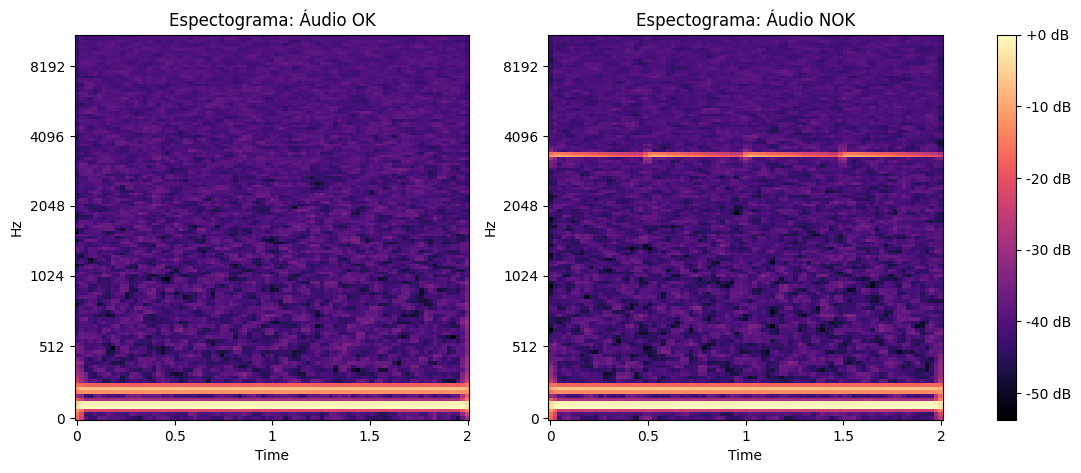

In [8]:
# apenas para visualização se o espectograma está sendo gerado corretamente
ok_signature, ok_spec = create_spectrogram(*ok_signals[0])
nok_signature, nok_spec = create_spectrogram(*nok_signals[0])

fig, ax = plt.subplots(1,2,figsize=(14,5))
librosa.display.specshow(ok_spec, sr=ok_signals[0][1], x_axis='time', y_axis='mel',
                         ax=ax[0], cmap='magma')
ax[0].set_title('Espectograma: Áudio OK')

librosa.display.specshow(nok_spec, sr=ok_signals[0][1], x_axis='time', y_axis='mel',
                         ax=ax[1], cmap='magma')
ax[1].set_title('Espectograma: Áudio NOK')
plt.colorbar(ax[1].collections[0], format='%+2.0f dB', ax=ax)
plt.show()

In [9]:
# separa áudios ok para treinar o detector de anomalias (se especializar no OK)
X_normal_train = np.array([create_spectrogram(audio, sr)[0] for audio, sr in ok_signals])

# separação dos áudios não ok para teste
X_test_nok = np.array([create_spectrogram(audio, sr)[0] for audio, sr in nok_signals])
# separação dos áudios ok para teste
X_test_ok = X_normal_train[:20]
# separação dos áudios misturados (ok e não ok) para teste
X_test_ok_nok = np.vstack((X_test_ok, X_test_nok))

In [11]:
# construímos um gabarito do que seria a resposta correta do detector de anomalia (1=normal,-1=anormal)
y_real = np.array([1]*len(X_test_ok) + [-1]*len(X_test_nok))
display(y_real)

array([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1])

In [13]:
# treina o modelo com o algoritmo de Isolation Forest apenas com dados normais
model = IsolationForest(contamination=0.05, random_state=42)
model.fit(X_normal_train)

IsolationForest(contamination=0.05, random_state=42)

In [14]:
predict = model.predict(X_test_ok_nok)
print("Resultado da Classificação (1=normal,-1=anormal)")
print(classification_report(y_real, predict))

Resultado da Classificação (1=normal,-1=anormal)
              precision    recall  f1-score   support

          -1       0.83      0.25      0.38        20
           1       0.56      0.95      0.70        20

    accuracy                           0.60        40
   macro avg       0.70      0.60      0.54        40
weighted avg       0.70      0.60      0.54        40



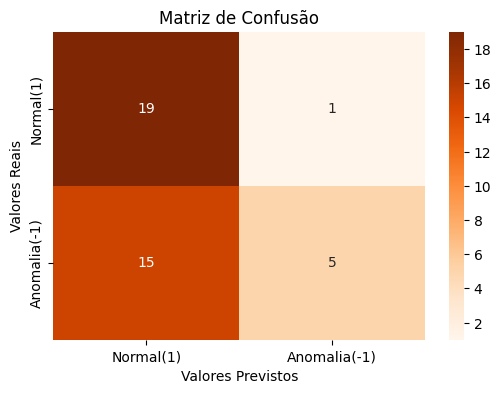

In [15]:
matrix = confusion_matrix(y_real, predict, labels=[1, -1])
plt.figure(figsize=(6,4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Normal(1)','Anomalia(-1)'],
            yticklabels=['Normal(1)','Anomalia(-1)'])
plt.title('Matriz de Confusão')
plt.ylabel('Valores Reais')
plt.xlabel('Valores Previstos')
plt.show()